## 1. Libraries and data loading

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import ScalarFormatter
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#when run as a plain script (main.py train), plt.show() opens chart windows are drawn offscreen instead of waiting for each one to be closed
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")

In [2]:
path = "listings.csv"

data = pd.read_csv(path)
data.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,23203785,https://www.airbnb.com/rooms/23203785,20260917204740,2026-09-21,NaN,"Apartamentos de Simone, Apartamento Picasso",<b>The space</b><br />Exceptional location in ...,NaN,https://a0.muscache.com/pictures/1554f91c-93a5...,16177101,...,4.86,4.84,4.43,NaN,NaN,5,5,0,0,0.38
1,23205290,https://www.airbnb.com/rooms/23205290,20260917204740,2026-09-19,NaN,Hermosilla III by Home at Homes,Perfect property if you need to come to Madrid...,NaN,https://a0.muscache.com/pictures/25b805c2-6051...,9228673,...,4.55,5.00,4.34,Spain - National registration number<br />ESFC...,NaN,4,4,0,0,0.45
2,23210760,https://www.airbnb.com/rooms/23210760,20260917204740,2026-09-19,NaN,A wonderful corner at the Retiro Park,A bright and quiet corner just a few steps fro...,NaN,https://a0.muscache.com/pictures/a16890ac-c757...,36433297,...,4.94,4.94,4.85,Spain - National registration number<br />ESFC...,NaN,1,1,0,0,6.77
3,23226721,https://www.airbnb.com/rooms/23226721,20260917204740,2026-09-20,NaN,Céntrico y Cómodo Estudio en Atocha-Retiro WIFI,"Nice and comfortable studio, very quiet and wi...",NaN,https://a0.muscache.com/pictures/15a5f6b5-f0b8...,172793556,...,4.89,4.83,4.68,Spain - National registration number<br />ESFC...,NaN,1,1,0,0,0.45
4,23269747,https://www.airbnb.com/rooms/23269747,20260917204740,2026-09-20,NaN,5 Stars Short-Term Rental apartment at Plaza M...,You'll love it. It is the ideal apartment to e...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,105322983,...,5.00,4.98,4.96,Spain - National registration number<br />ESFC...,NaN,1,1,0,0,3.61


In [3]:
np.random.seed(55)

Chart style: the Airbnb palette, set as the default colour cycle for every plot below.

In [4]:
# Project palette (Airbnb)
PRIMARY = "#ff5a5f"     # main series
SECONDARY = "#00a699"   # second series / negative values
ACCENT = "#fc642d"      # highlights
INK = "#484848"         # main text, reference lines
INK_MUTED = "#767676"   # secondary text, axes
GRID = "#ebebeb"
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_primary", ["#ffd1d2", PRIMARY, "#a3262a"])

In [5]:
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[PRIMARY, SECONDARY, INK]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.edgecolor": INK_MUTED, "axes.labelcolor": INK_MUTED,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "text.color": INK, "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.titlesize": 11,
    "boxplot.boxprops.color": INK,
    "boxplot.medianprops.color": PRIMARY,
    "boxplot.whiskerprops.color": INK_MUTED,
    "boxplot.capprops.color": INK_MUTED,
    "boxplot.flierprops.markeredgecolor": INK_MUTED,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

## 2. Exploratory data analysis

In [6]:
data.info()   # column names, dtypes and non-null counts

<class 'pandas.DataFrame'>
RangeIndex: 23109 entries, 0 to 23108
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            23109 non-null  int64  
 1   listing_url                                   23109 non-null  str    
 2   scrape_id                                     23109 non-null  int64  
 3   last_scraped                                  23109 non-null  str    
 4   source                                        6025 non-null   str    
 5   name                                          23109 non-null  str    
 6   description                                   22965 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   23108 non-null  str    
 9   host_id                                       23109 non-null  int64  
 1

We will only keep the columns that do not have personal data from the hosts, keeping in mind the GDPR minimization principle, and the fact that they provide no useful information, and add only noise and effort to the data.

In [7]:
PII_COLS = [
    "host_name", "host_about", "host_url", "host_picture_url",
    "host_thumbnail_url", "host_profile_url", "host_profile_id", "host_location",
]

In [8]:
def remove_pii(df, pii_cols):
    return df.drop(columns=pii_cols, errors="ignore")

In [9]:
data = remove_pii(data, PII_COLS)
data.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,...,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,23203785,https://www.airbnb.com/rooms/23203785,20260917204740,2026-09-21,NaN,"Apartamentos de Simone, Apartamento Picasso",<b>The space</b><br />Exceptional location in ...,NaN,https://a0.muscache.com/pictures/1554f91c-93a5...,16177101,NaN,12,3,11,6,...,2025-04-28,4.54,4.76,4.76,4.78,4.86,4.84,4.43,NaN,NaN,5,5,0,0,0.38
1,23205290,https://www.airbnb.com/rooms/23205290,20260917204740,2026-09-19,NaN,Hermosilla III by Home at Homes,Perfect property if you need to come to Madrid...,NaN,https://a0.muscache.com/pictures/25b805c2-6051...,9228673,NaN,12,11,12,11,...,2025-11-18,4.53,4.70,4.66,4.70,4.55,5.00,4.34,Spain - National registration number<br />ESFC...,NaN,4,4,0,0,0.45
2,23210760,https://www.airbnb.com/rooms/23210760,20260917204740,2026-09-19,NaN,A wonderful corner at the Retiro Park,A bright and quiet corner just a few steps fro...,NaN,https://a0.muscache.com/pictures/a16890ac-c757...,36433297,NaN,11,2,11,2,...,2026-09-14,4.91,4.93,4.93,4.87,4.94,4.94,4.85,Spain - National registration number<br />ESFC...,NaN,1,1,0,0,6.77
3,23226721,https://www.airbnb.com/rooms/23226721,20260917204740,2026-09-20,NaN,Céntrico y Cómodo Estudio en Atocha-Retiro WIFI,"Nice and comfortable studio, very quiet and wi...",NaN,https://a0.muscache.com/pictures/15a5f6b5-f0b8...,172793556,NaN,8,7,8,7,...,2026-06-20,4.77,4.77,4.74,4.77,4.89,4.83,4.68,Spain - National registration number<br />ESFC...,NaN,1,1,0,0,0.45
4,23269747,https://www.airbnb.com/rooms/23269747,20260917204740,2026-09-20,NaN,5 Stars Short-Term Rental apartment at Plaza M...,You'll love it. It is the ideal apartment to e...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,105322983,NaN,9,9,8,7,...,2026-09-11,5.00,4.99,4.99,4.99,5.00,4.98,4.96,Spain - National registration number<br />ESFC...,NaN,1,1,0,0,3.61


Identifying the null values in our data

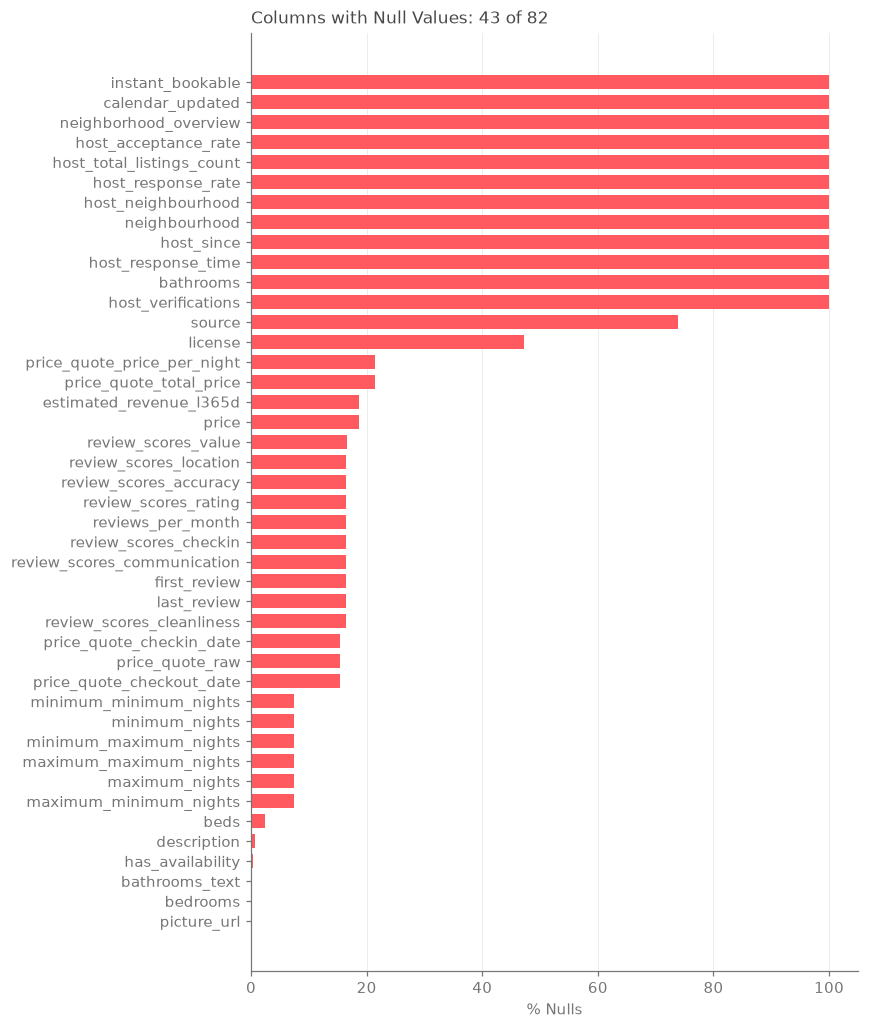

In [10]:
na_pct = (data.isna().mean() * 100).sort_values()
na_pct = na_pct[na_pct > 0]
fig, ax = plt.subplots(figsize=(8, max(4, 0.22 * len(na_pct))))
ax.barh(na_pct.index, na_pct.values, color=PRIMARY, height=0.7)
ax.set_xlabel("% Nulls")
ax.set_title(f"Columns with Null Values: {len(na_pct)} of {data.shape[1]}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [11]:
data["price_num"] = pd.to_numeric(data["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
no_price = data["price_num"].isna()
print(f"Listings without price: {no_price.sum():,} ({no_price.mean():.1%})\n")

def profile(mask):
    d = data[mask]
    return pd.Series({
        "n": len(d),
        "% availability_365 == 0": (d["availability_365"] == 0).mean() * 100,
        "% has_availability == 't'": (d["has_availability"] == "t").mean() * 100,
        "% with reviews in last 12m": (d["number_of_reviews_ltm"] > 0).mean() * 100,
        "median total reviews": d["number_of_reviews"].median(),
    })

print(pd.DataFrame({"no price": profile(no_price), "with price": profile(~no_price)}).round(1).to_string())

Listings without price: 4,324 (18.7%)

                            no price  with price
n                             4324.0     18785.0
% availability_365 == 0         75.6        12.1
% has_availability == 't'       88.5        82.4
% with reviews in last 12m      31.2        78.6
median total reviews             4.0        32.0


In [12]:
data_with_price = data.loc[data["price_num"].notna()].copy()
print(f"Listings with a price: {len(data_with_price):,}")

Listings with a price: 18,785


In [13]:
data_recent_reviews = data_with_price.loc[
    data_with_price["number_of_reviews_ltm"] > 0
].copy()

print(f"Listings with recent reviews: {len(data_recent_reviews):,}")

Listings with recent reviews: 14,766


Which of our variables are numerical and which are categorical? Columns that are entirely null are dropped first.

In [14]:
var_df = data_recent_reviews.dropna(axis=1, how="all")

num_vars = var_df.select_dtypes(include=[np.number]).columns.tolist()
cat_vars = var_df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical variables ({len(num_vars)}):")
print(num_vars)
print()
print(f"Categorical variables ({len(cat_vars)}):")
print(cat_vars)
print()
print("Categorical cardinality:")
print(var_df[cat_vars].nunique().sort_values(ascending=False).to_string())

Numerical variables (47):
['id', 'scrape_id', 'host_id', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_listings_count', 'latitude', 'longitude', 'accommodates', 'bedrooms', 'beds', 'price_quote_total_price', 'price_quote_price_per_night', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'estimated_revenue_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'calculated_host_listings_count', 'calculated_host_listings_co

count    14766.0
mean       190.7
std        161.8
min         12.0
1%          27.0
5%          47.0
25%        104.0
50%        156.0
75%        227.0
95%        446.2
99%        792.1
max       6049.0 

Top 10 highest prices:
       price_num        room_type                property_type  accommodates  bedrooms  minimum_nights  number_of_reviews_ltm
19127    6049.00     Private room  Private room in rental unit             2       1.0             1.0                     36
18256    3512.00  Entire home/apt    Entire serviced apartment             3       1.0             1.0                     41
6634     2965.33  Entire home/apt           Entire rental unit             6       6.0             3.0                      1
3045     2395.00  Entire home/apt           Entire rental unit            10       6.0             1.0                     19
20170    2300.00  Entire home/apt           Entire rental unit             3       1.0             1.0                      2
5014     2243.1

C:\Users\luis.j.gomez\AppData\Local\Temp\ipykernel_10140\391536400.py:41: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2].boxplot(positive_price, vert=False, widths=0.5)


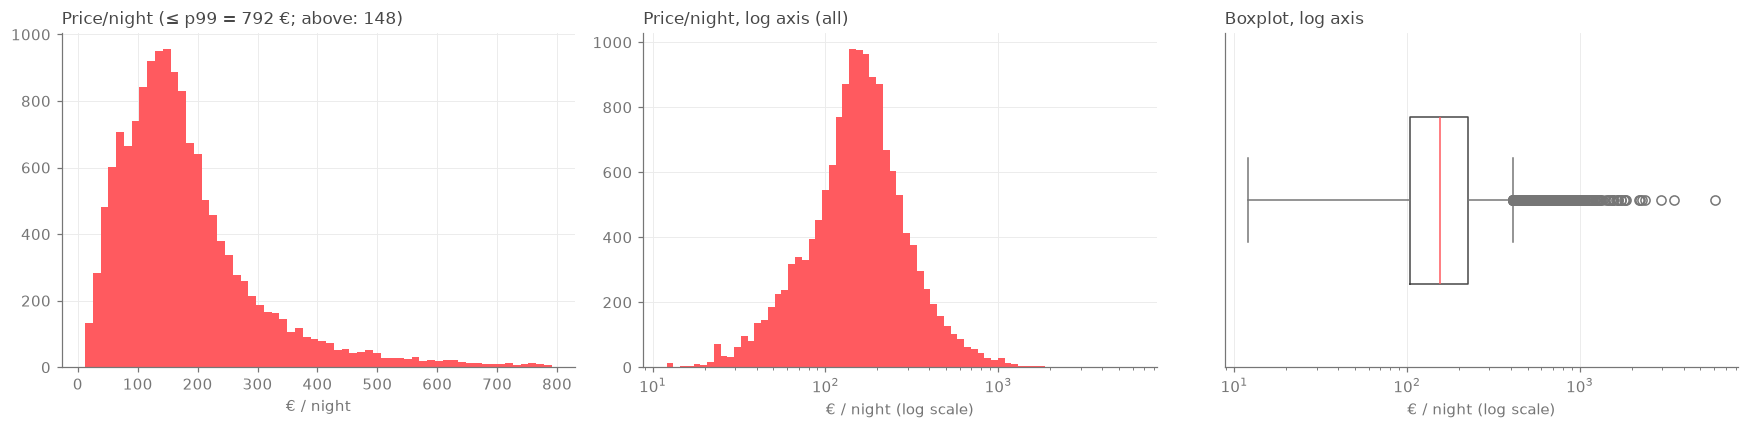

In [15]:
price = data_recent_reviews["price_num"].dropna()

print(
    price.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
    .round(1)
    .to_string(),
    "\n",
)
print("Top 10 highest prices:")
print(
    data_recent_reviews.loc[
        price.nlargest(10).index,
        [
            "price_num", "room_type", "property_type", "accommodates",
            "bedrooms", "minimum_nights", "number_of_reviews_ltm",
        ],
    ].to_string()
)

# Log axes need strictly positive prices
positive_price = price[price > 0]
p99 = positive_price.quantile(.99)
log_bins = np.logspace(
    np.log10(positive_price.min()),
    np.log10(positive_price.max()),
    70,
)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(positive_price[positive_price <= p99], bins=60, color=PRIMARY)
axes[0].set_title(
    f"Price/night (≤ p99 = {p99:.0f} €; above: {(positive_price > p99).sum()})"
)
axes[0].set_xlabel("€ / night")

axes[1].hist(positive_price, bins=log_bins, color=PRIMARY)
axes[1].set_xscale("log")
axes[1].set_title("Price/night, log axis (all)")
axes[1].set_xlabel("€ / night (log scale)")

axes[2].boxplot(positive_price, vert=False, widths=0.5)
axes[2].set_xscale("log")
axes[2].set_yticks([])
axes[2].set_title("Boxplot, log axis")
axes[2].set_xlabel("€ / night (log scale)")

plt.tight_layout()
plt.show()

What is the distribution of our numeric columns?

                                                count          mean           std           min           50%           95%           99%           max
id                                            14766.0  9.543833e+17  6.098610e+17  3.032000e+04  1.126762e+18  1.704244e+18  1.744217e+18  1.772483e+18
scrape_id                                     14766.0  2.026092e+13  0.000000e+00  2.026092e+13  2.026092e+13  2.026092e+13  2.026092e+13  2.026092e+13
host_id                                       14766.0  3.372085e+16  2.374415e+17  1.745300e+04  2.912537e+08  7.254744e+08  1.700697e+18  1.768282e+18
hosts_time_as_user_years                      14766.0  6.600000e+00  4.200000e+00  0.000000e+00  7.000000e+00  1.300000e+01  1.500000e+01  1.700000e+01
hosts_time_as_user_months                     14766.0  5.600000e+00  3.400000e+00  0.000000e+00  6.000000e+00  1.100000e+01  1.100000e+01  1.100000e+01
hosts_time_as_host_years                      14766.0  5.400000e+00  3.900000e+00  0.000

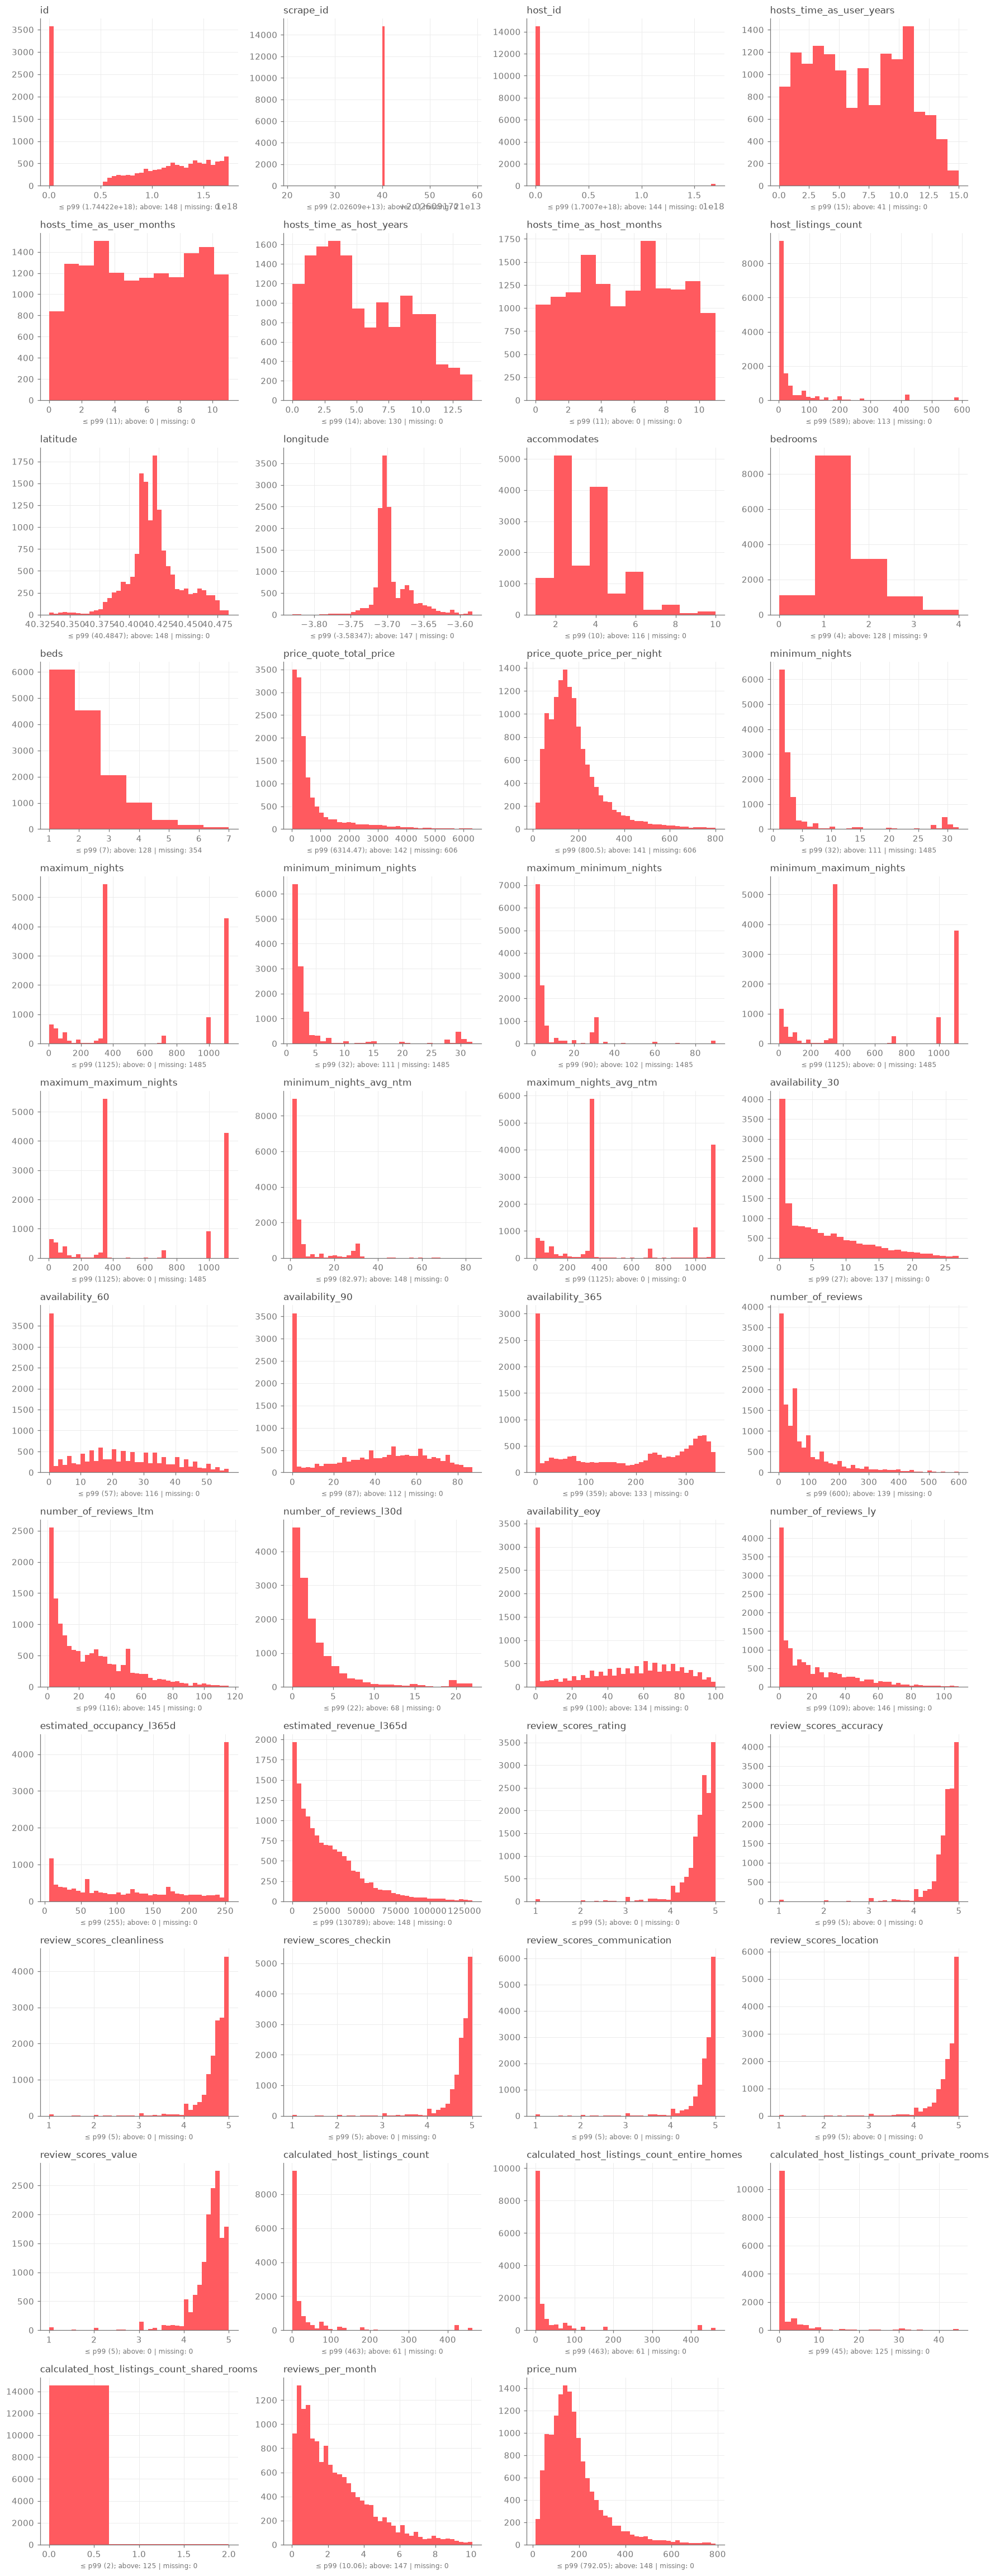

In [16]:
eda_data = data_recent_reviews
print(
    eda_data[num_vars]
    .describe(percentiles=[.5, .95, .99])
    .T.round(1)
    .to_string()
)

n_cols = 4
n_rows = int(np.ceil(len(num_vars) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.5 * n_rows))
for ax, col in zip(axes.flat, num_vars):
    values = eda_data[col].dropna()
    if values.empty:
        ax.set_title(f"{col} (no data)")
        continue

    q99 = values.quantile(.99)
    shown = values[values <= q99]
    ax.hist(shown, bins=min(40, max(shown.nunique(), 2)), color=PRIMARY)
    ax.set_title(col)
    ax.set_xlabel(
        f"≤ p99 ({q99:g}); above: {(values > q99).sum()} "
        f"| missing: {eda_data[col].isna().sum()}",
        fontsize=8,
    )

for ax in axes.flat[len(num_vars):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Now, what is the distribution of our categorical variables?

Neighbourhoods (neighbourhood_cleansed): 126 | Districts (neighbourhood_group_cleansed): 21


C:\Users\luis.j.gomez\AppData\Local\Temp\ipykernel_10140\2902663538.py:32: UserWarning: Glyph 127968 (\N{HOUSE BUILDING}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\luis.j.gomez\OneDrive - Accenture\Desktop\IE\daiist-env-setup\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127968 (\N{HOUSE BUILDING}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


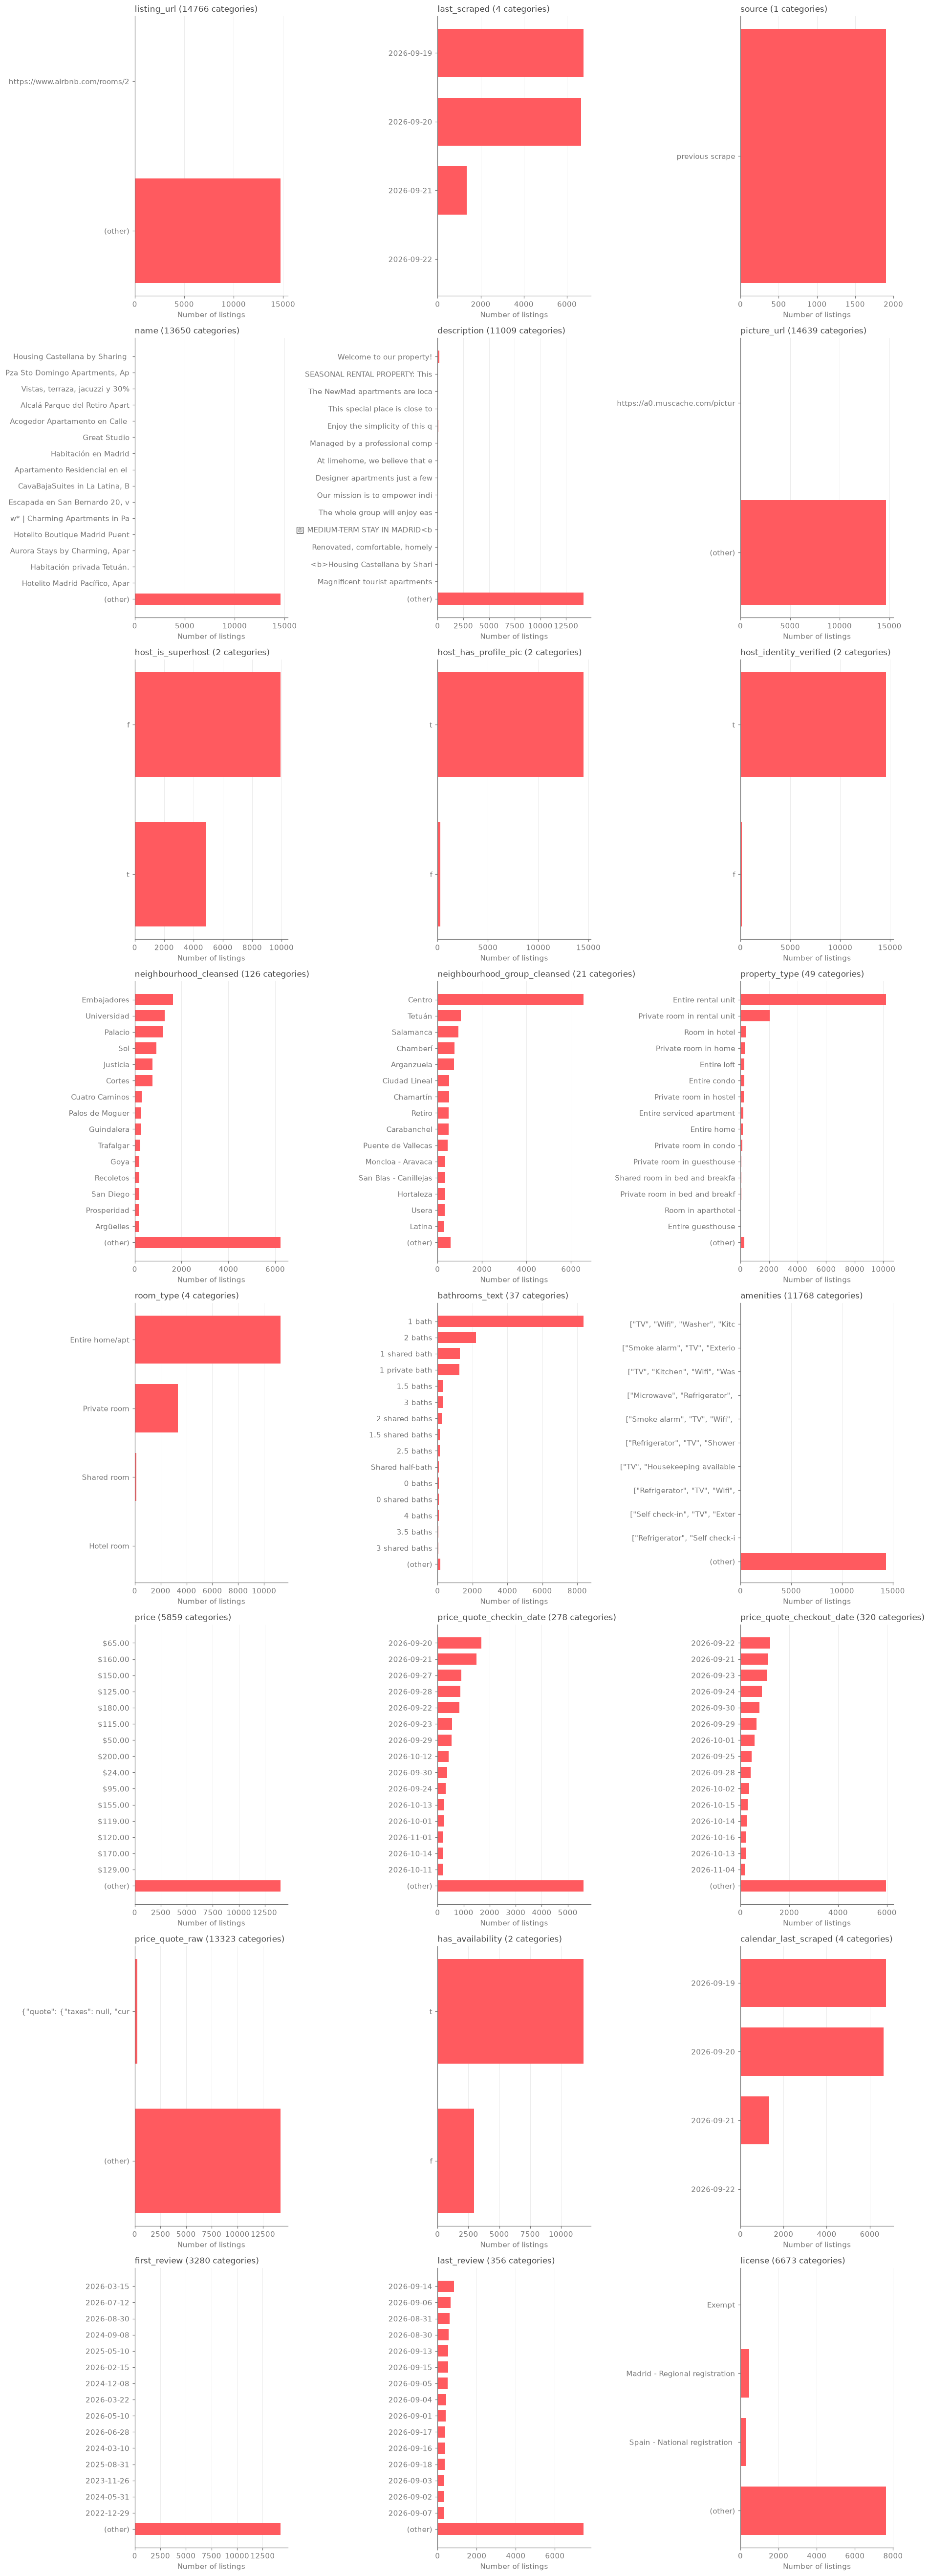

In [17]:
print(
    f"Neighbourhoods (neighbourhood_cleansed): "
    f"{eda_data['neighbourhood_cleansed'].nunique()} | "
    f"Districts (neighbourhood_group_cleansed): "
    f"{eda_data['neighbourhood_group_cleansed'].nunique()}"
)

TOP_CATS = 15

n_cols = 3
n_rows = int(np.ceil(len(cat_vars) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(17, 6 * n_rows))

for ax, col in zip(axes.flat, cat_vars):
    vc = eda_data[col].value_counts()

    if len(vc) > TOP_CATS:
        vc = pd.concat([
            vc.iloc[:TOP_CATS],
            pd.Series({"(other)": vc.iloc[TOP_CATS:].sum()}),
        ])

    vc = vc.iloc[::-1]
    ax.barh(vc.index.astype(str).str[:30], vc.values, color=PRIMARY, height=0.7)
    ax.set_title(f"{col} ({eda_data[col].nunique()} categories)")
    ax.set_xlabel("Number of listings")
    ax.grid(axis="y", visible=False)

for ax in axes.flat[len(cat_vars):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

Price vs. the other variables

### 2.1 Price by room type and district

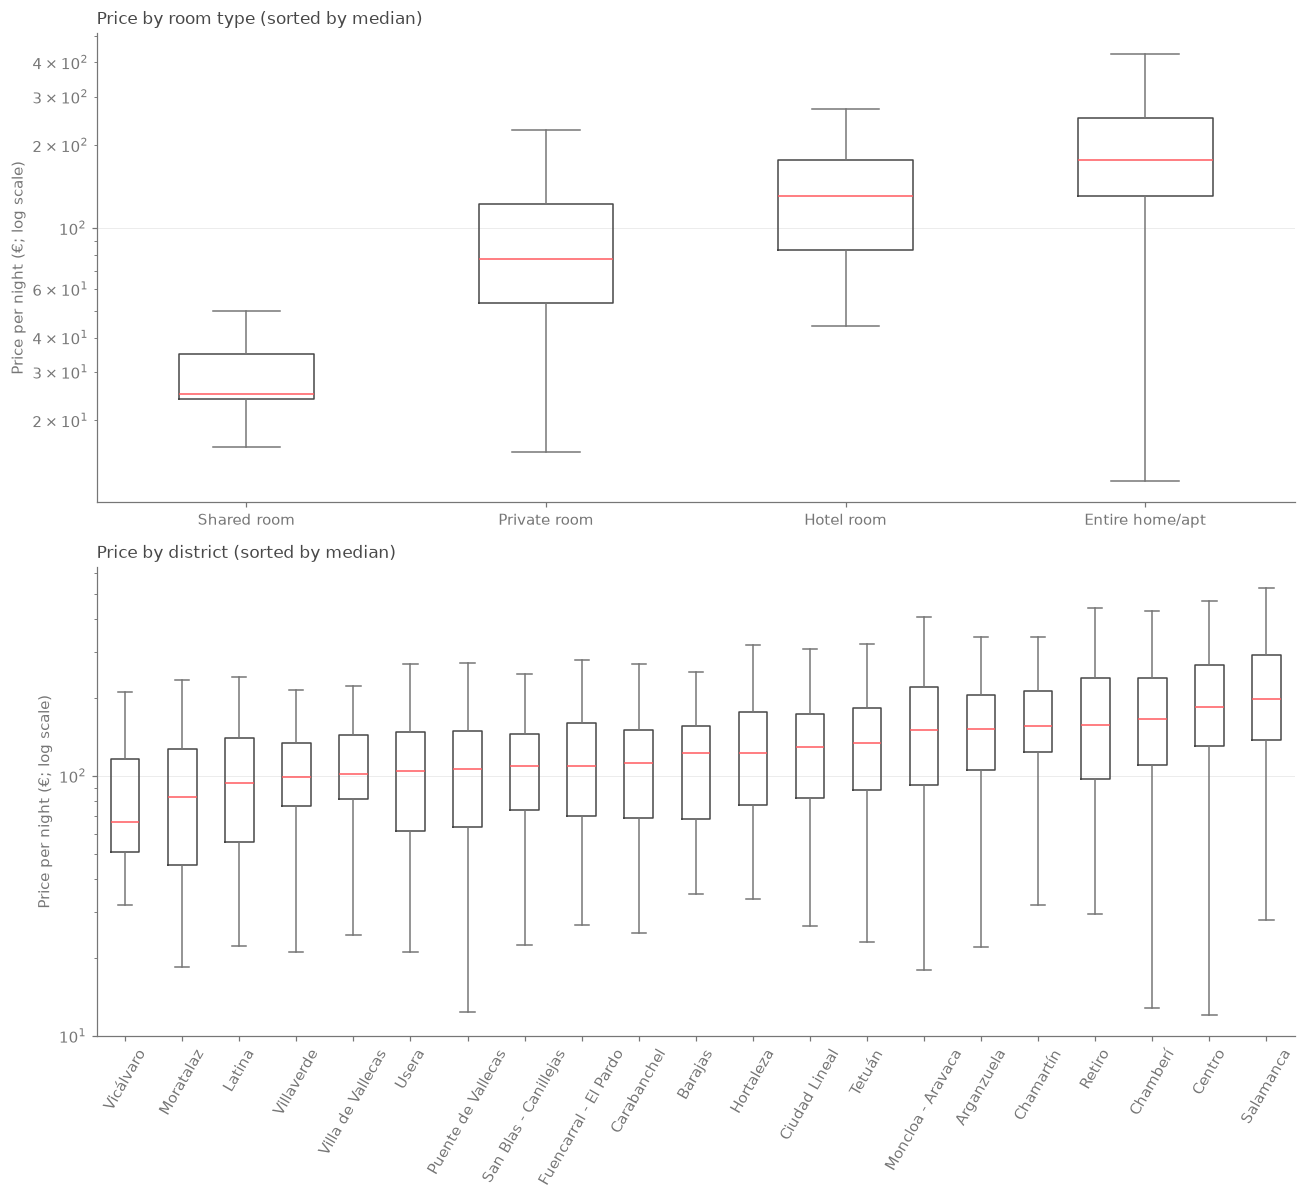

In [18]:
plot_data = eda_data.loc[
    eda_data["price_num"].gt(0)
    & eda_data["room_type"].notna()
    & eda_data["neighbourhood_group_cleansed"].notna()
]

fig, axes = plt.subplots(2, 1, figsize=(12, 11))

for ax, column, title, rotate in [
    (axes[0], "room_type", "Price by room type", 0),
    (axes[1], "neighbourhood_group_cleansed", "Price by district", 60),
]:
    groups = (
        plot_data.groupby(column)["price_num"]
        .agg(list)
    )
    groups = groups.reindex(
        plot_data.groupby(column)["price_num"].median().sort_values().index
    )

    ax.boxplot(groups.tolist(), tick_labels=groups.index, showfliers=False)
    ax.set_yscale("log")
    ax.set_title(f"{title} (sorted by median)")
    ax.set_ylabel("Price per night (€; log scale)")
    ax.tick_params(axis="x", labelrotation=rotate)
    ax.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

### 2.2 Capacity against price

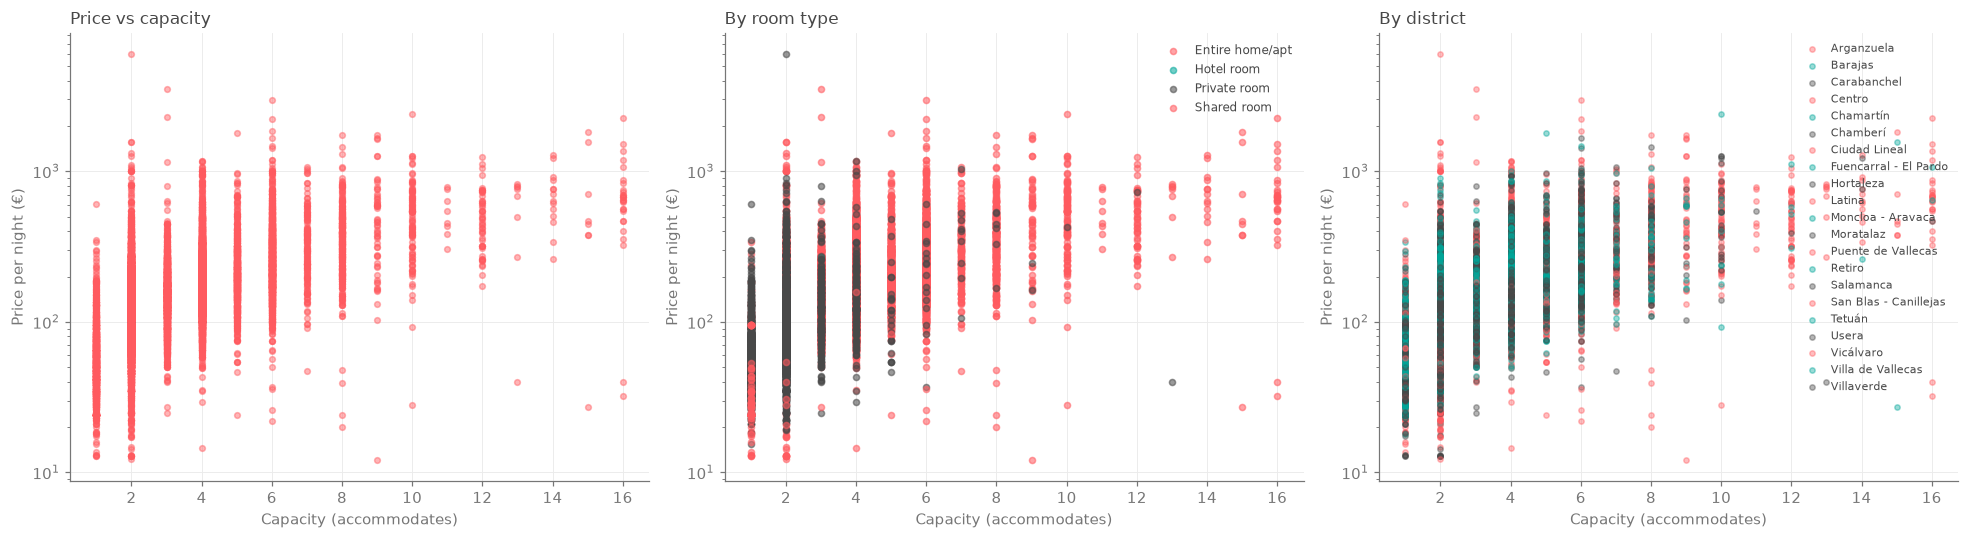

In [19]:
scatter_df = eda_data.loc[
    eda_data["price_num"].gt(0) &
    eda_data["accommodates"].gt(0)
].copy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Overall capacity vs price
axes[0].scatter(
    scatter_df["accommodates"],
    scatter_df["price_num"],
    s=14,
    alpha=0.45,
    color=PRIMARY,
)
axes[0].set_title("Price vs capacity")
axes[0].set_xlabel("Capacity (accommodates)")
axes[0].set_ylabel("Price per night (€)")
axes[0].set_yscale("log")

# 2) By room type
for room_type, group in scatter_df.groupby("room_type"):
    axes[1].scatter(
        group["accommodates"],
        group["price_num"],
        s=16,
        alpha=0.55,
        label=room_type,
    )
axes[1].set_title("By room type")
axes[1].set_xlabel("Capacity (accommodates)")
axes[1].set_ylabel("Price per night (€)")
axes[1].set_yscale("log")
axes[1].legend(frameon=False, fontsize=8)

# 3) By district
for district, group in scatter_df.groupby("neighbourhood_group_cleansed"):
    axes[2].scatter(
        group["accommodates"],
        group["price_num"],
        s=12,
        alpha=0.4,
        label=district,
    )
axes[2].set_title("By district")
axes[2].set_xlabel("Capacity (accommodates)")
axes[2].set_ylabel("Price per night (€)")
axes[2].set_yscale("log")
axes[2].legend(frameon=False, fontsize=7)

plt.tight_layout()
plt.show()

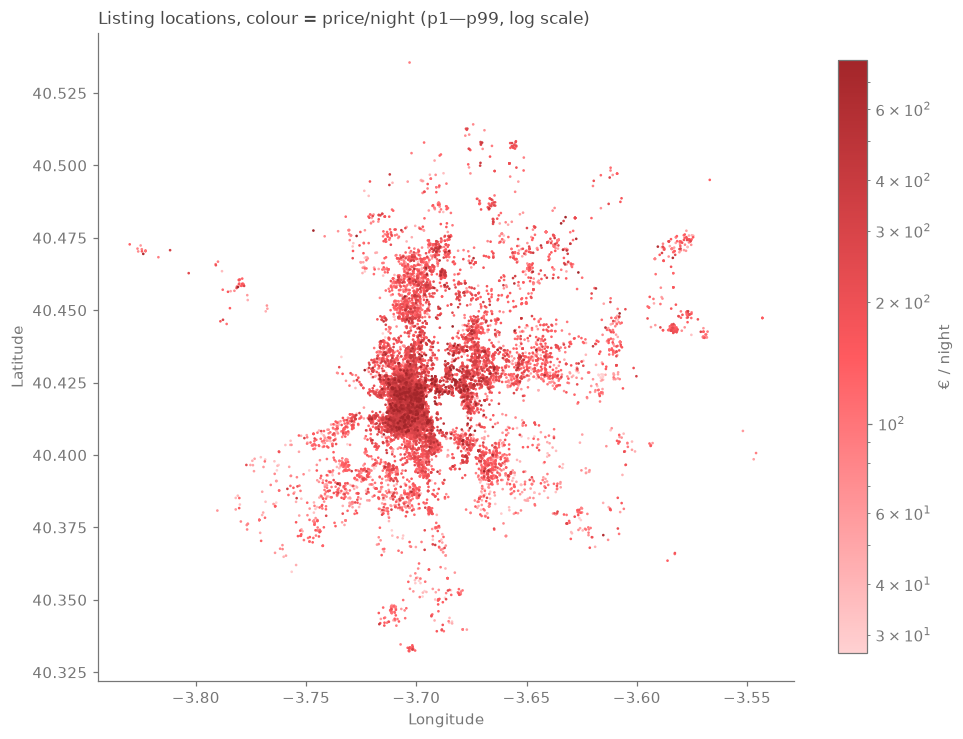

In [20]:
priced = eda_data.loc[
    eda_data["price_num"].gt(0)
    & eda_data["longitude"].notna()
    & eda_data["latitude"].notna()
].copy()

lo, hi = priced["price_num"].quantile([0.01, 0.99])
m = priced.sort_values("price_num")  # Most expensive listings are drawn on top

fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(
    m["longitude"],
    m["latitude"],
    c=m["price_num"].clip(lo, hi),
    cmap=SEQ_CMAP,
    norm=LogNorm(vmin=lo, vmax=hi),
    s=3,
    linewidths=0,
)
ax.set_aspect(1 / np.cos(np.radians(m["latitude"].mean())))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Listing locations, colour = price/night (p1—p99, log scale)")
ax.grid(False)
fig.colorbar(sc, ax=ax, shrink=0.7, label="€ / night")
plt.tight_layout()
plt.show()

### 2.3 Recent reviews as a demand signal

Measure how much real demand there is by comparing the prices of listings with recent (<12 months) reviews against those without.

In [21]:
price_review = data_with_price.loc[data_with_price["price_num"] > 0].copy()
has_demand = price_review["number_of_reviews_ltm"] > 0

print(f"Listings with a positive price: {len(price_review):,}")
print(f"  with reviews in last 12 months: {has_demand.sum():,} ({has_demand.mean():.1%})")
print(f"  without reviews in last 12 months: {(~has_demand).sum():,}\n")

group_labels = has_demand.map({
    True: "reviews in 12m",
    False: "no reviews in 12m",
})
print(
    price_review.groupby(group_labels)["price_num"]
    .describe(percentiles=[.05, .5, .95])
    .round(1)
    .to_string()
)

# Limit the plot to p99.5 so extreme prices do not compress the distributions.
price_cap = price_review["price_num"].quantile(.995)
plot_prices = price_review.loc[price_review["price_num"] <= price_cap]
plot_demand = has_demand.loc[plot_prices.index]
bins = np.logspace(
    np.log10(plot_prices["price_num"].min()),
    np.log10(price_cap),
    60,
)

Listings with a positive price: 18,785
  with reviews in last 12 months: 14,766 (78.6%)
  without reviews in last 12 months: 4,019

                         count   mean     std   min    5%    50%    95%      max
number_of_reviews_ltm                                                           
no reviews in 12m       4019.0  274.3  1131.3   9.1  27.1  125.8  603.2  36883.0
reviews in 12m         14766.0  190.7   161.8  12.0  47.0  156.0  446.2   6049.0


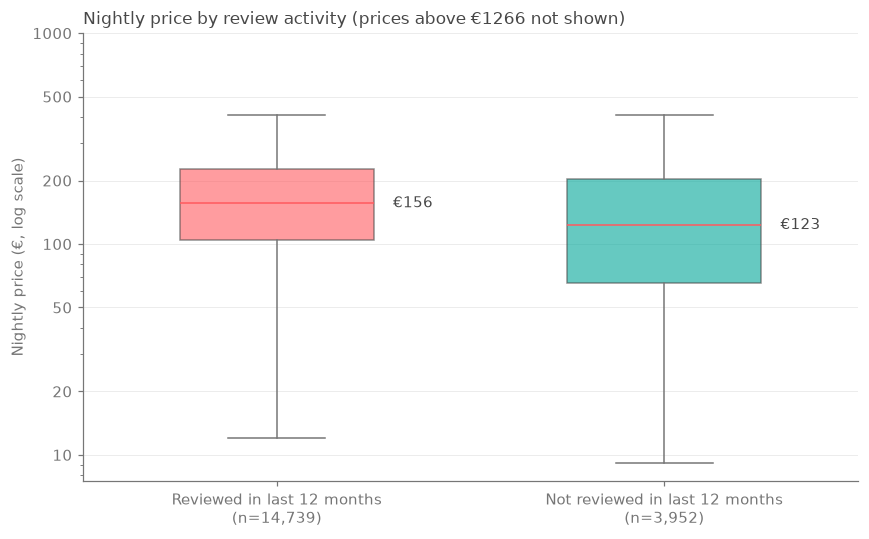

In [22]:
reviewed = plot_prices.loc[plot_demand, "price_num"]
not_reviewed = plot_prices.loc[~plot_demand, "price_num"]

fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot(
    [reviewed, not_reviewed],
    tick_labels=[
        f"Reviewed in last 12 months\n(n={len(reviewed):,})",
        f"Not reviewed in last 12 months\n(n={len(not_reviewed):,})",
    ],
    widths=0.5,
    patch_artist=True,
    showfliers=False,
)
for patch, color in zip(bp["boxes"], [PRIMARY, SECONDARY]):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

for i, values in enumerate([reviewed, not_reviewed], start=1):
    ax.text(i + 0.3, values.median(), f"€{values.median():.0f}", va="center", color=INK)

ax.set_yscale("log")
ax.set_yticks([10, 20, 50, 100, 200, 500, 1000])
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylabel("Nightly price (€, log scale)")
ax.set_title(f"Nightly price by review activity (prices above €{price_cap:.0f} not shown)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()


## 3. Cleaning and feature engineering

### 3.1 Data cleaning

Keep the prices from the last 12 months to feed the model so that it will learn from what the market actually wants, instead of ask prices. After this demand adjustment, remove duplicates and missing IDs, parse and adapt columns to their proper data types i.e.: parse price_num to numeric, add boolean flags and impute missing values either with the median (numeric) or "unknown" (categorical), and delete rows with impossible values i.e.: coordinates outside Madrid. The reduced column set remaining is made up of the columns that could become features.

In [23]:
df_clean = data_recent_reviews.copy()

3.1.1 Drop exact duplicates and rows without a listing ID

In [24]:
df_clean = df_clean.drop_duplicates(subset="id").copy()
df_clean = df_clean.dropna(subset=["id"]).copy()

3.1.2 Parse `price_num` as a number

In [25]:
df_clean["price_num"] = pd.to_numeric(
    df_clean["price"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce",
)
df_clean = df_clean[df_clean["price_num"].gt(0)].copy()

3.1.3 Create Airbnb-relevant boolean flags

In [26]:
for col in [
    "host_is_superhost",
    "host_has_profile_pic",
    "host_identity_verified",
    "has_availability",
    "instant_bookable",
]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].replace({"t": True, "f": False})

3.1.4 Convert date columns

In [27]:
for col in ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]:
    if col in df_clean.columns:
        df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

3.1.5 Drop columns that are entirely, or more than 90%, null

In [28]:
null_frac = df_clean.isna().mean()
drop_cols = null_frac[null_frac > 0.90].index
df_clean = df_clean.drop(columns=drop_cols, errors="ignore")

3.1.6 Fill missing categorical and numerical values

In [29]:
cat_cols = df_clean.select_dtypes(include=["object", "category"]).columns
for c in cat_cols:
    df_clean[c] = df_clean[c].fillna("Unknown")

num_cols = df_clean.select_dtypes(include=[np.number]).columns
for c in num_cols:
    if c == "price_num":
        continue
    if df_clean[c].isna().any():
        df_clean[c] = df_clean[c].fillna(df_clean[c].median())

C:\Users\luis.j.gomez\AppData\Local\Temp\ipykernel_10140\1615018869.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include=["object", "category"]).columns


3.1.7 Delete impossible values

In [30]:
df_clean = df_clean[
    df_clean["latitude"].between(40.1, 41.2) &
    df_clean["longitude"].between(-4.1, -3.2) &
    df_clean["accommodates"].gt(0)
].copy()

3.1.8 Keep a practical feature set to feed the model

In [31]:
model_cols = [
    "id",
    "neighbourhood_cleansed",
    "neighbourhood_group_cleansed",
    "property_type",
    "room_type",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms_text",
    "amenities",
    "host_is_superhost",
    "host_has_profile_pic",
    "host_identity_verified",
    "host_listings_count",
    "hosts_time_as_user_years",
    "hosts_time_as_user_months",
    "hosts_time_as_host_years",
    "hosts_time_as_host_months",
    "has_availability",
    "availability_30",
    "availability_60",
    "availability_90",
    "availability_365",
    "number_of_reviews",
    "number_of_reviews_ltm",
    "review_scores_rating",
    "review_scores_accuracy",
    "review_scores_cleanliness",
    "review_scores_checkin",
    "review_scores_communication",
    "review_scores_location",
    "review_scores_value",
    "latitude",
    "longitude",
    "price_num",
]

df_clean = df_clean[[c for c in model_cols if c in df_clean.columns]].copy()
df_clean = df_clean.reset_index(drop=True)

df_clean.head()

,id,neighbourhood_cleansed,neighbourhood_group_cleansed,property_type,room_type,accommodates,bedrooms,beds,bathrooms_text,amenities,host_is_superhost,host_has_profile_pic,host_identity_verified,host_listings_count,hosts_time_as_user_years,...,availability_60,availability_90,availability_365,number_of_reviews,number_of_reviews_ltm,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,latitude,longitude,price_num
0,23205290,Recoletos,Salamanca,Entire rental unit,Entire home/apt,2,1.0,2.0,1 bath,"[""Baby bath"", ""Refrigerator"", ""TV"", ""Shower ge...",True,True,True,58,12,...,39,69,83,47,2,4.53,4.70,4.66,4.70,4.55,5.00,4.34,40.425290,-3.683830,387.29
1,23210760,Ibiza,Retiro,Entire rental unit,Entire home/apt,6,2.0,3.0,1 bath,"[""Smoke alarm"", ""Refrigerator"", ""Self check-in...",True,True,True,1,11,...,15,26,93,707,116,4.91,4.93,4.93,4.87,4.94,4.94,4.85,40.419770,-3.676940,274.00
2,23226721,Embajadores,Centro,Entire rental unit,Entire home/apt,2,0.0,1.0,1 bath,"[""Refrigerator"", ""TV"", ""Wifi"", ""Cooking basics...",False,True,True,3,8,...,11,41,131,47,3,4.77,4.77,4.74,4.77,4.89,4.83,4.68,40.406330,-3.698371,66.67
3,23269747,Sol,Centro,Entire rental unit,Entire home/apt,6,2.0,5.0,2 baths,"[""Ecologistel shampoo"", ""Smoke alarm"", ""Pack \...",True,True,True,1,9,...,16,41,183,377,52,5.00,4.99,4.99,4.99,5.00,4.98,4.96,40.414429,-3.707760,414.00
4,23288641,Palacio,Centro,Entire rental unit,Entire home/apt,6,3.0,4.0,1.5 baths,"[""Smoke alarm"", ""Pack \u2019n play/Travel crib...",True,True,True,5,14,...,27,45,308,348,52,4.90,4.92,4.91,4.95,4.96,4.93,4.82,40.409120,-3.710250,259.67


### 3.2 Feature engineering

Turning the cleaned columns into features to be fed to a linear model and that relate to nightly prices.

3.2.1 Parse the bathroom count: it's a direct size and quality signal, since more bathrooms generally mean a bigger place

In [32]:
bathroom_text = df_clean["bathrooms_text"].fillna("").astype(str)
df_clean["bathrooms_num"] = pd.to_numeric(
    bathroom_text.str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce",
)
df_clean.loc[
    df_clean["bathrooms_num"].isna()
    & bathroom_text.str.contains("half", case=False),
    "bathrooms_num",
] = 0.5

3.2.2 Count listed amenities, since more amenities are an indicator of a more expensive listing

In [33]:
amenities = df_clean["amenities"].fillna("[]").astype(str)
df_clean["amenity_count"] = (
    amenities.str.count(",") + 1
).where(amenities.ne("[]"), 0)

# Combine host tenure years and months.
for prefix in ["hosts_time_as_user", "hosts_time_as_host"]:
    years = f"{prefix}_years"
    months = f"{prefix}_months"
    if years in df_clean.columns and months in df_clean.columns:
        df_clean[f"{prefix}_total_months"] = (
            df_clean[years] * 12 + df_clean[months]
        )

3.2.3 Map boolean fields to 1/0 (-1 for unknown)

In [34]:
for col in [
    "host_is_superhost",
    "host_has_profile_pic",
    "host_identity_verified",
    "has_availability",
    "instant_bookable",
]:
    if col in df_clean.columns:
        df_clean[col] = (
            df_clean[col]
            .map({"t": 1, "f": 0, True: 1, False: 0, "Unknown": -1})
            .fillna(-1)
            .astype("int8")
        )

3.2.4 Simplified capacity and review features

In [35]:
df_clean["guests_per_bedroom"] = (
    df_clean["accommodates"] / df_clean["bedrooms"].clip(lower=1)
)
review_cols = [
    c for c in df_clean.columns
    if c.startswith("review_scores_")
]
if review_cols:
    df_clean["review_score_mean"] = df_clean[review_cols].mean(axis=1)

3.2.5 Approximate distance to Sol (the city centre)

In [36]:
lat1 = np.radians(df_clean["latitude"])
lat2 = np.radians(40.4168)
delta_lat = lat2 - lat1
delta_lon = np.radians(-3.7038 - df_clean["longitude"])
a = (
    np.sin(delta_lat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2
)
df_clean["distance_to_sol_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

3.2.6 Prepare the target variable and the features

In [37]:
y = df_clean["price_num"].copy()
X = df_clean.drop(
    columns=[
        "id",
        "price_num",
        "amenities",
        "bathrooms_text",
        "estimated_revenue_l365d",
        "estimated_occupancy_l365d",
    ],
    errors="ignore",
).copy()

In [38]:
print(f"Feature matrix: {X.shape}")
print(f"Target: {y.shape}")
X.head()

Feature matrix: (14766, 38)
Target: (14766,)


,neighbourhood_cleansed,neighbourhood_group_cleansed,property_type,room_type,accommodates,bedrooms,beds,host_is_superhost,host_has_profile_pic,host_identity_verified,host_listings_count,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,...,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,latitude,longitude,bathrooms_num,amenity_count,hosts_time_as_user_total_months,hosts_time_as_host_total_months,guests_per_bedroom,review_score_mean,distance_to_sol_km
0,Recoletos,Salamanca,Entire rental unit,Entire home/apt,2,1.0,2.0,1,1,1,58,12,11,12,11,...,4.70,4.66,4.70,4.55,5.00,4.34,40.425290,-3.683830,1.0,31,155,155,2.0,4.640000,1.936249
1,Ibiza,Retiro,Entire rental unit,Entire home/apt,6,2.0,3.0,1,1,1,1,11,2,11,2,...,4.93,4.93,4.87,4.94,4.94,4.85,40.419770,-3.676940,1.0,40,134,134,3.0,4.910000,2.297722
2,Embajadores,Centro,Entire rental unit,Entire home/apt,2,0.0,1.0,0,1,1,3,8,7,8,7,...,4.77,4.74,4.77,4.89,4.83,4.68,40.406330,-3.698371,1.0,22,103,103,2.0,4.778571,1.251663
3,Sol,Centro,Entire rental unit,Entire home/apt,6,2.0,5.0,1,1,1,1,9,9,8,7,...,4.99,4.99,4.99,5.00,4.98,4.96,40.414429,-3.707760,2.0,67,117,103,3.0,4.987143,0.426525
4,Palacio,Centro,Entire rental unit,Entire home/apt,6,3.0,4.0,1,1,1,5,14,1,8,7,...,4.92,4.91,4.95,4.96,4.93,4.82,40.409120,-3.710250,1.5,39,169,103,2.0,4.912857,1.013645


## 4. Data preprocessing and splits

### 4.1 Outlier removal

The highest nightly prices are treated as outliers and removed, since various extreme listings (up to €6,000/night) can add bias to the linear model's squared-error loss. We set the cutoff point by OUTLIER_QUANTILE.

In [39]:
OUTLIER_QUANTILE = 0.99

price_cutoff = df_clean["price_num"].quantile(OUTLIER_QUANTILE)
is_outlier = df_clean["price_num"] > price_cutoff
print(f"Price cutoff (p{OUTLIER_QUANTILE * 100:g}): €{price_cutoff:.2f}/night")
print(f"Removing {is_outlier.sum():,} of {len(df_clean):,} listings ({is_outlier.mean():.1%})")

df_clean = df_clean.loc[~is_outlier].reset_index(drop=True)
y = y.loc[~is_outlier.values].reset_index(drop=True)
X = X.loc[~is_outlier.values].reset_index(drop=True)
print(f"Feature matrix: {X.shape} | Target: {y.shape} | max price: €{y.max():.2f}")

Price cutoff (p99): €792.05/night
Removing 148 of 14,766 listings (1.0%)
Feature matrix: (14618, 38) | Target: (14618,) | max price: €791.00


### 4.2 Train / validation / test split

Random 70/15/15 split. The validation set is used to tune the regularization strength and the learning rate, and the test set is used only for the final comparison.

In [40]:
SEED = 55

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:>5}: {len(part):,} rows ({len(part) / len(y):.1%}) | "
          f"median price €{part.median():.0f}")

train: 10,232 rows (70.0%) | median price €155
  val: 2,193 rows (15.0%) | median price €156
 test: 2,193 rows (15.0%) | median price €153


### 4.3 Target transformation

Price is right-skewed, so the models are trained on log1p(price).

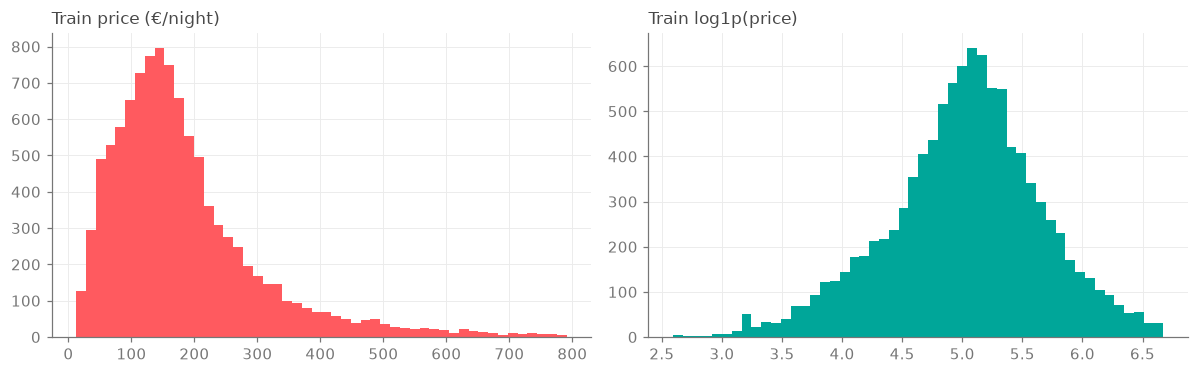

Skewness raw: 1.70 | log1p: -0.30


In [41]:
y_train_log = np.log1p(y_train)
y_val_log = np.log1p(y_val)
y_test_log = np.log1p(y_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(y_train, bins=50, color=PRIMARY)
axes[0].set_title("Train price (€/night)")
axes[1].hist(y_train_log, bins=50, color=SECONDARY)
axes[1].set_title("Train log1p(price)")
plt.tight_layout()
plt.show()

print(f"Skewness raw: {y_train.skew():.2f} | log1p: {y_train_log.skew():.2f}")

### 4.4 Collinearity

Features are dropped automatically when VIF a threshold of 10, one at a time the feature with the highest VIF is removed and VIFs are recalculated until every remaining feature is at or below the threshold.

In [42]:
CAT_FEATURES = [
    "neighbourhood_cleansed",
    "neighbourhood_group_cleansed",
    "property_type",
    "room_type",
]
BINARY_FEATURES = [
    c for c in X_train.columns
    if c not in CAT_FEATURES and set(X_train[c].unique()) <= {-1, 0, 1}
]
NUM_FEATURES = [
    c for c in X_train.columns
    if c not in CAT_FEATURES and c not in BINARY_FEATURES
]
print(f"Numeric features before VIF: {len(NUM_FEATURES)}\n")

VIF_THRESHOLD = 10


def compute_vif(df):
    # VIF_j = 1 / (1 - R^2_j), regressing column j on all the others
    Z = ((df - df.mean()) / df.std(ddof=0)).fillna(0).to_numpy()
    vifs = {}
    for j, col in enumerate(df.columns):
        others = np.delete(Z, j, axis=1)
        coef, *_ = np.linalg.lstsq(others, Z[:, j], rcond=None)
        resid = Z[:, j] - others @ coef
        r2 = 1 - resid.var() / Z[:, j].var() if Z[:, j].var() > 0 else 1.0
        vifs[col] = np.inf if r2 >= 1 - 1e-9 else 1 / (1 - r2)
    return pd.Series(vifs, name="VIF")


vif_before = compute_vif(X_train[NUM_FEATURES])
print("VIF before dropping (highest first):")
print(vif_before.sort_values(ascending=False).round(1).to_string())

dropped_vif = []
kept = list(NUM_FEATURES)
while True:
    vif = compute_vif(X_train[kept])
    worst = vif.idxmax()
    if vif[worst] <= VIF_THRESHOLD:
        break
    dropped_vif.append((worst, vif[worst]))
    kept.remove(worst)

print("\nDropped, in order:")
for name, v in dropped_vif:
    print(f"  {name:<40} VIF = {v:,.1f}")

NUM_FEATURES = kept
vif_after = compute_vif(X_train[NUM_FEATURES])

print(f"\nFinal feature set ({len(CAT_FEATURES) + len(NUM_FEATURES) + len(BINARY_FEATURES)} features "
      f"before one-hot encoding)")
print(f"\nNumeric ({len(NUM_FEATURES)}), with VIF after dropping:")
print(vif_after.sort_values(ascending=False).round(2).to_string())
print(f"\nRemaining numeric features after VIF removal ({len(NUM_FEATURES)}):")
print(NUM_FEATURES)
print(f"\nBinary flags ({len(BINARY_FEATURES)}): {BINARY_FEATURES}")
print(f"\nCategorical ({len(CAT_FEATURES)}): {CAT_FEATURES}")

Numeric features before VIF: 30

VIF before dropping (highest first):
hosts_time_as_user_years            inf
hosts_time_as_user_months           inf
hosts_time_as_host_months           inf
hosts_time_as_host_years            inf
hosts_time_as_host_total_months     inf
review_score_mean                   inf
hosts_time_as_user_total_months     inf
review_scores_value                 inf
review_scores_location              inf
review_scores_communication         inf
review_scores_checkin               inf
review_scores_cleanliness           inf
review_scores_accuracy              inf
review_scores_rating                inf
availability_60                    25.3
availability_90                    17.7
availability_30                     5.5
accommodates                        3.4
bedrooms                            2.5
guests_per_bedroom                  2.2
distance_to_sol_km                  2.1
number_of_reviews                   2.1
availability_365                    2.1
number_of_

### 4.5 Categorical encoding, scaling and full preprocessor

We one-hot encode categorical features so each category gets its own coefficient instead of an artificial order. Categories with fewer than MIN_CATEGORY_COUNT training listings are grouped together in an infrequent column reduce noise from coefficients, as well as any categories unseen in training.

Continuous features are standardized (mean 0, std 1) with a StandardScaler and the 0/1 flags are passed through as they were.

Encoder and scaler are combined in ColumnTransformer, which is wrapped in a pipeline and fitted only on the training set. 
The validation and test sets are only transformed. Use joblib to save the fitted pipeline so that Gradio doesn't need to retrain anything to transform new inputs with exactly the same encoder categories and scaler stats.

In [43]:
MIN_CATEGORY_COUNT = 30
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)

column_transformer = ColumnTransformer(
    [
        ("cat", OneHotEncoder(
            drop="first",
            min_frequency=MIN_CATEGORY_COUNT,
            handle_unknown="infrequent_if_exist",
            sparse_output=False,
        ), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES),
        ("bin", "passthrough", BINARY_FEATURES),
    ],
    verbose_feature_names_out=False,
)
preprocessor = Pipeline([("preprocess", column_transformer)])

X_train_t = preprocessor.fit_transform(X_train).astype("float32")
X_val_t = preprocessor.transform(X_val).astype("float32")
X_test_t = preprocessor.transform(X_test).astype("float32")
feature_names = preprocessor.get_feature_names_out()

print(f"Transformed shapes: train {X_train_t.shape} | val {X_val_t.shape} | test {X_test_t.shape}")

cat_enc = column_transformer.named_transformers_["cat"]
for feature, cats, infreq in zip(
    CAT_FEATURES, cat_enc.categories_, cat_enc.infrequent_categories_
):
    n_infreq = 0 if infreq is None else len(infreq)
    print(f"{feature:<30} {len(cats):>3} levels -> {n_infreq:>3} grouped as infrequent")

num_idx = [i for i, n in enumerate(feature_names) if n in NUM_FEATURES]
print(f"\nTrain scaled mean (max |mean|): {np.abs(X_train_t[:, num_idx].mean(axis=0)).max():.4f}")
print(f"Train scaled std (min / max):   {X_train_t[:, num_idx].std(axis=0).min():.3f} / "
      f"{X_train_t[:, num_idx].std(axis=0).max():.3f}")
print(f"NaNs in any split: {np.isnan(X_train_t).any() or np.isnan(X_val_t).any() or np.isnan(X_test_t).any()}")

joblib.dump(preprocessor, MODELS_DIR / "preprocessor.joblib")
print(f"\nSaved fitted preprocessor to {MODELS_DIR / 'preprocessor.joblib'}")

Transformed shapes: train (10232, 132) | val (2193, 132) | test (2193, 132)
neighbourhood_cleansed         126 levels ->  60 grouped as infrequent
neighbourhood_group_cleansed    21 levels ->   1 grouped as infrequent
property_type                   46 levels ->  32 grouped as infrequent
room_type                        4 levels ->   1 grouped as infrequent

Train scaled mean (max |mean|): nan
Train scaled std (min / max):   nan / nan
NaNs in any split: True

Saved fitted preprocessor to models\preprocessor.joblib


c:\Users\luis.j.gomez\OneDrive - Accenture\Desktop\IE\daiist-env-setup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\luis.j.gomez\OneDrive - Accenture\Desktop\IE\daiist-env-setup\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


### 4.6 Naive baseline

In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def regression_metrics(y_true_log, y_pred_log):
    y_true_log = np.asarray(y_true_log).ravel()
    y_pred_log = np.asarray(y_pred_log).ravel()
    y_true_eur, y_pred_eur = np.expm1(y_true_log), np.expm1(y_pred_log)
    return {
        "RMSE (log)": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE (log)": mean_absolute_error(y_true_log, y_pred_log),
        "R2 (log)": r2_score(y_true_log, y_pred_log),
        "RMSE (€)": np.sqrt(mean_squared_error(y_true_eur, y_pred_eur)),
        "MAE (€)": mean_absolute_error(y_true_eur, y_pred_eur),
    }


baseline_value = float(np.median(y_train_log))
print(f"Baseline prediction: log1p(price) = {baseline_value:.4f} -> €{np.expm1(baseline_value):.2f}/night\n")

baseline_results = pd.DataFrame({
    "val": regression_metrics(y_val_log, np.full(len(y_val_log), baseline_value)),
    "test": regression_metrics(y_test_log, np.full(len(y_test_log), baseline_value)),
}).T
print(baseline_results.round(3).to_string())

Baseline prediction: log1p(price) = 5.0516 -> €155.26/night

      RMSE (log)  MAE (log)  R2 (log)  RMSE (€)  MAE (€)
val        0.626      0.481    -0.003   116.266   79.561
test       0.633      0.483    -0.009   117.994   78.955


### 4.7 Tensors for the PyTorch models

In [45]:
X_train_t = np.nan_to_num(X_train_t, nan=0.0)
X_val_t = np.nan_to_num(X_val_t, nan=0.0)
X_test_t = np.nan_to_num(X_test_t, nan=0.0)

X_train_tensor = torch.tensor(X_train_t, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_t, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_t, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_log.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val_log.to_numpy(), dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test_log.to_numpy(), dtype=torch.float32).reshape(-1, 1)

n_features = X_train_tensor.shape[1]

for name, xt, yt in [
    ("train", X_train_tensor, y_train_tensor),
    ("val", X_val_tensor, y_val_tensor),
    ("test", X_test_tensor, y_test_tensor),
]:
    print(f"{name:>5}: X {tuple(xt.shape)} {xt.dtype} | y {tuple(yt.shape)} {yt.dtype}")
print(f"NaNs remaining: {np.isnan(X_train_t).sum() + np.isnan(X_val_t).sum() + np.isnan(X_test_t).sum()}")

train: X (10232, 132) torch.float32 | y (10232, 1) torch.float32
  val: X (2193, 132) torch.float32 | y (2193, 1) torch.float32
 test: X (2193, 132) torch.float32 | y (2193, 1) torch.float32
NaNs remaining: 0


## 5. Model training

### 5.1 Scikit-learn Ridge regression

Ridge adds L2 regularisation to normal least squares, which shrinks large coefficients and adds stability when there exists correlation between features. We choose regularisation strength (alpha) by scanning 5 values on the validation set.

In [46]:
from sklearn.linear_model import Ridge

best_alpha, best_val_rmse = None, float("inf")
for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
    candidate = Ridge(alpha=alpha).fit(X_train_t, y_train_log)
    rmse = regression_metrics(y_val_log, candidate.predict(X_val_t))["RMSE (log)"]
    print(f"alpha={alpha:6.2f}  val RMSE (log) {rmse:.4f}")
    if rmse < best_val_rmse:
        best_val_rmse, best_alpha = rmse, alpha

print(f"\nbest alpha: {best_alpha}")

sklearn_model = Ridge(alpha=best_alpha).fit(X_train_t, y_train_log)
val_preds_sk = sklearn_model.predict(X_val_t)
test_preds_sk = sklearn_model.predict(X_test_t)

sklearn_results = pd.DataFrame({
    "val": regression_metrics(y_val_log, val_preds_sk),
    "test": regression_metrics(y_test_log, test_preds_sk),
}).T
print("\nScikit-learn Ridge results:")
print(sklearn_results.round(3).to_string())

joblib.dump(sklearn_model, MODELS_DIR / "sklearn_ridge.joblib")
print(f"\nSaved to {MODELS_DIR / 'sklearn_ridge.joblib'}")

alpha=  0.01  val RMSE (log) 0.3895
alpha=  0.10  val RMSE (log) 0.3895
alpha=  1.00  val RMSE (log) 0.3895
alpha= 10.00  val RMSE (log) 0.3900
alpha=100.00  val RMSE (log) 0.3977

best alpha: 1.0

Scikit-learn Ridge results:
      RMSE (log)  MAE (log)  R2 (log)  RMSE (€)  MAE (€)
val        0.390      0.289     0.612    84.776   52.254
test       0.395      0.295     0.607    86.143   53.181

Saved to models\sklearn_ridge.joblib


### 5.2 Manual PyTorch

Like in Session 5's PyTorch intro notebook, the gradient descent has been written by hand and the learning-rate tuning in 5.4 can reuse it unchanged.

In [47]:
torch.manual_seed(SEED)

def forward_manual(X, w, b):
    return X @ w + b   

def mse_manual(y_pred, y_true):
    return ((y_pred.squeeze(-1) - y_true.squeeze(-1)) ** 2).mean()

def train_manual(lr, n_epochs, verbose=False):
    w = torch.zeros(n_features, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    loss_history, val_history = [], []

    for epoch in range(n_epochs):
        y_pred = forward_manual(X_train_tensor, w, b)
        loss = mse_manual(y_pred, y_train_tensor)

        loss.backward()

        with torch.no_grad():        
            w -= lr * w.grad
            b -= lr * b.grad

        w.grad.zero_()                
        b.grad.zero_()

        loss_history.append(loss.item())
        with torch.no_grad():
            val_history.append(mse_manual(forward_manual(X_val_tensor, w, b), y_val_tensor).item())

        if verbose and epoch % 100 == 0:
            print(f"epoch {epoch:3d}  train MSE {loss_history[-1]:.4f}  val MSE {val_history[-1]:.4f}")

    return w, b, loss_history, val_history

lr_manual = 0.05
n_epochs = 500
w_manual, b_manual, loss_hist_man, val_hist_man = train_manual(lr_manual, n_epochs, verbose=True)

with torch.no_grad():
    val_preds_man = forward_manual(X_val_tensor, w_manual, b_manual).numpy()
    test_preds_man = forward_manual(X_test_tensor, w_manual, b_manual).numpy()

manual_results = pd.DataFrame({
    "val": regression_metrics(y_val_log, val_preds_man),
    "test": regression_metrics(y_test_log, test_preds_man),
}).T
print("\nManual PyTorch results:")
print(manual_results.round(3).to_string())

epoch   0  train MSE 25.5743  val MSE 7.8935
epoch 100  train MSE 0.2695  val MSE 0.2562
epoch 200  train MSE 0.2370  val MSE 0.2228
epoch 300  train MSE 0.2221  val MSE 0.2080
epoch 400  train MSE 0.2130  val MSE 0.1993

Manual PyTorch results:
      RMSE (log)  MAE (log)  R2 (log)  RMSE (€)  MAE (€)
val        0.440      0.326     0.505    89.722   56.691
test       0.456      0.343     0.475    93.346   58.818


### 5.3 Standard PyTorch

The loop lives in train_nn for the same reason as in sub-section 5.2.

In [48]:
import torch.nn as nn

loss_fn = nn.MSELoss()

def train_nn(lr, n_epochs, verbose=False):
    model = nn.Linear(n_features, 1)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_history, val_history = [], []

    for epoch in range(n_epochs):
        model.train()
        optimizer.zero_grad()
        y_pred = model(X_train_tensor).squeeze(-1)
        loss = loss_fn(y_pred, y_train_tensor.squeeze(-1))
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val_tensor).squeeze(-1), y_val_tensor.squeeze(-1))
        val_history.append(val_loss.item())

        if verbose and epoch % 100 == 0:
            print(f"epoch {epoch:3d}  train MSE {loss_history[-1]:.4f}  val MSE {val_history[-1]:.4f}")

    model.eval()
    return model, loss_history, val_history

torch.manual_seed(SEED)
model_nn, loss_hist_nn, val_hist_nn = train_nn(lr=0.01, n_epochs=n_epochs, verbose=True)

with torch.no_grad():
    val_preds_nn = model_nn(X_val_tensor).squeeze(-1).numpy()
    test_preds_nn = model_nn(X_test_tensor).squeeze(-1).numpy()

nn_results = pd.DataFrame({
    "val": regression_metrics(y_val_log, val_preds_nn),
    "test": regression_metrics(y_test_log, test_preds_nn),
}).T
print("\nStandard PyTorch (nn.Module) results:")
print(nn_results.round(3).to_string())

epoch   0  train MSE 23.9111  val MSE 23.1428
epoch 100  train MSE 0.5571  val MSE 0.5377
epoch 200  train MSE 0.3293  val MSE 0.3222
epoch 300  train MSE 0.2673  val MSE 0.2620
epoch 400  train MSE 0.2458  val MSE 0.2411

Standard PyTorch (nn.Module) results:
      RMSE (log)  MAE (log)  R2 (log)  RMSE (€)  MAE (€)
val        0.481      0.366     0.407    97.870   63.327
test       0.487      0.375     0.401    97.402   64.091


### 5.4 Hyperparameter tuning

In [49]:
test_preds_man_pre = test_preds_man.copy()
test_preds_nn_pre = test_preds_nn.copy()

lr_candidates = [0.001, 0.01, 0.05, 0.1]
tune_epochs = 300

val_mse_man = {}
for lr in lr_candidates:
    w, b, loss_history, val_history = train_manual(lr, tune_epochs)
    val_mse_man[lr] = val_history[-1]
    print(f"manual  lr={lr:.3f}  val MSE {val_mse_man[lr]:.4f}")
best_lr_man = min(val_mse_man, key=val_mse_man.get)
print(f"best manual lr: {best_lr_man}\n")

val_mse_nn = {}
for lr in lr_candidates:
    model, loss_history, val_history = train_nn(lr, tune_epochs)
    val_mse_nn[lr] = val_history[-1]
    print(f"Adam    lr={lr:.3f}  val MSE {val_mse_nn[lr]:.4f}")
best_lr_nn = min(val_mse_nn, key=val_mse_nn.get)
print(f"best Adam lr: {best_lr_nn}")

manual  lr=0.001  val MSE 0.5100
manual  lr=0.010  val MSE 0.2862
manual  lr=0.050  val MSE 0.2081
manual  lr=0.100  val MSE 0.1886
best manual lr: 0.1

Adam    lr=0.001  val MSE 10.2916
Adam    lr=0.010  val MSE 0.2739
Adam    lr=0.050  val MSE 0.2011
Adam    lr=0.100  val MSE 0.1910
best Adam lr: 0.1


In [50]:
w_manual, b_manual, loss_hist_man, val_hist_man = train_manual(best_lr_man, n_epochs)
with torch.no_grad():
    test_preds_man = forward_manual(X_test_tensor, w_manual, b_manual).numpy()
torch.save({"w": w_manual.detach().clone(), "b": b_manual.detach().clone()}, MODELS_DIR / "manual_pytorch.pt")
print(f"Manual PyTorch retrained with lr={best_lr_man}, saved to {MODELS_DIR / 'manual_pytorch.pt'}")

model_nn, loss_hist_nn, val_hist_nn = train_nn(best_lr_nn, n_epochs)
with torch.no_grad():
    test_preds_nn = model_nn(X_test_tensor).squeeze(-1).numpy()
torch.save(model_nn.state_dict(), MODELS_DIR / "nn_pytorch.pt")
print(f"Standard PyTorch retrained with lr={best_lr_nn}, saved to {MODELS_DIR / 'nn_pytorch.pt'}")

Manual PyTorch retrained with lr=0.1, saved to models\manual_pytorch.pt
Standard PyTorch retrained with lr=0.1, saved to models\nn_pytorch.pt


Save held out test rows, true prices and baseline value for Gradio to rerun the saved preprocessor and models without retraining anything.

In [51]:
joblib.dump({"X_test": X_test, "y_test_log": y_test_log.to_numpy()}, MODELS_DIR / "test_set.joblib")
joblib.dump({"median_log_price": baseline_value}, MODELS_DIR / "baseline.joblib")
print(f"Saved test_set.joblib and baseline.joblib to {MODELS_DIR}")

Saved test_set.joblib and baseline.joblib to models


### 5.5 Three-method comparison

Test-set comparison:
                    RMSE (log)  MAE (log)  R2 (log)  RMSE (€)  MAE (€)
Naive baseline           0.633      0.483    -0.009   117.994   78.955
Scikit-learn Ridge       0.395      0.295     0.607    86.143   53.181
Manual PyTorch           0.433      0.327     0.527    90.755   57.086
Standard PyTorch         0.438      0.331     0.516    89.755   57.421


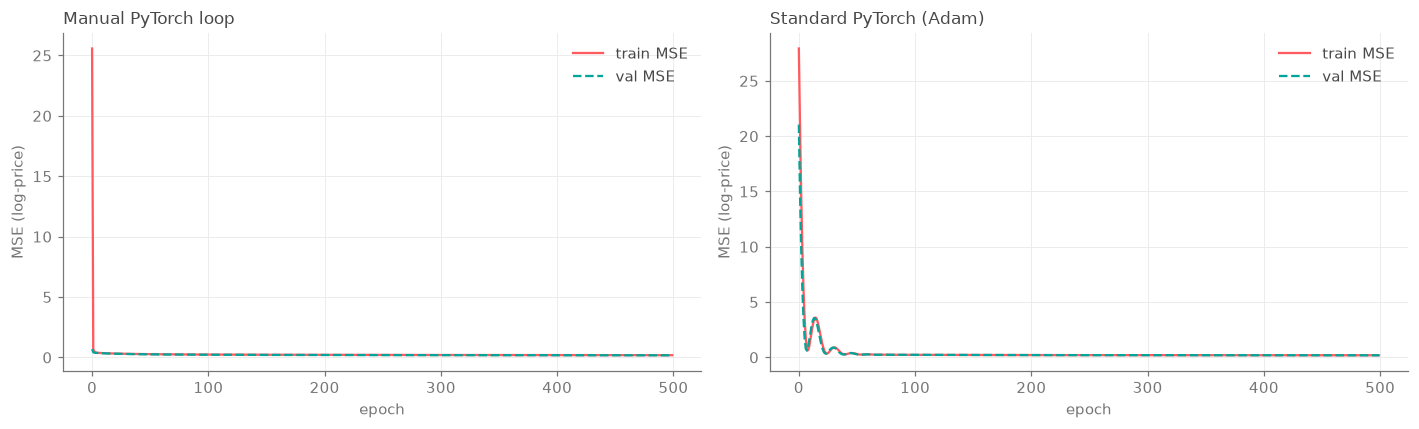

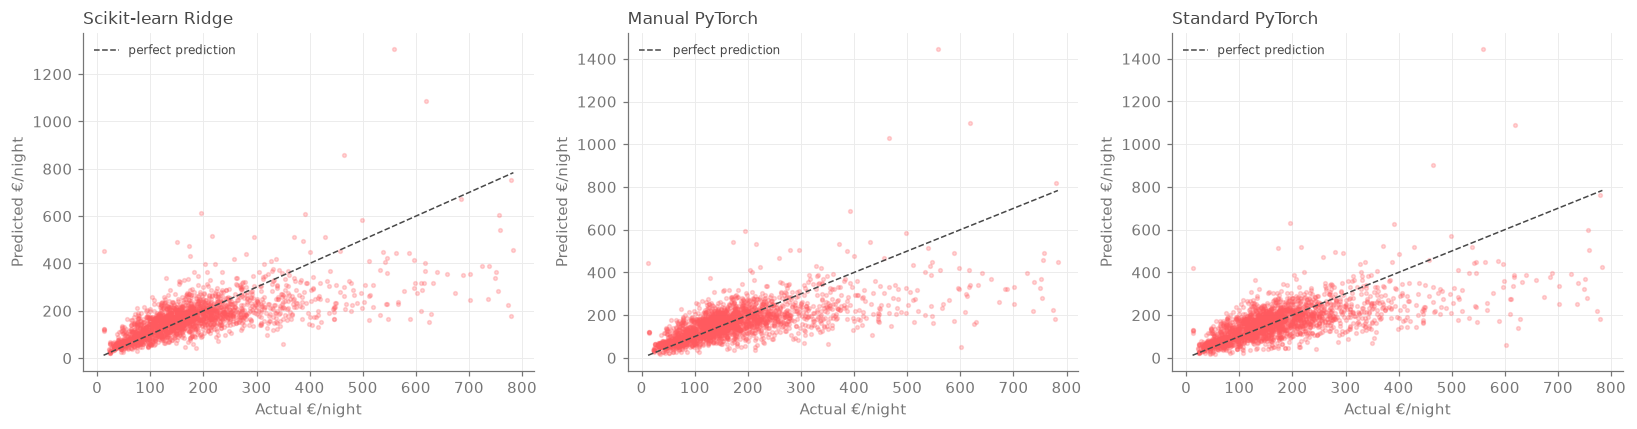

In [52]:
comparison = pd.DataFrame({
    "Naive baseline": regression_metrics(y_test_log, np.full(len(y_test_log), baseline_value)),
    "Scikit-learn Ridge": regression_metrics(y_test_log, test_preds_sk),
    "Manual PyTorch": regression_metrics(y_test_log, test_preds_man),
    "Standard PyTorch": regression_metrics(y_test_log, test_preds_nn),
}).T
print("Test-set comparison:")
print(comparison.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, train_hist, val_hist, title in [
    (axes[0], loss_hist_man, val_hist_man, "Manual PyTorch loop"),
    (axes[1], loss_hist_nn, val_hist_nn, "Standard PyTorch (Adam)"),
]:
    ax.plot(train_hist, color=PRIMARY, label="train MSE")
    ax.plot(val_hist, color=SECONDARY, linestyle="--", label="val MSE")
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.set_ylabel("MSE (log-price)")
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

y_true_eur = np.expm1(y_test_log.to_numpy())
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, preds, title in [
    (axes[0], test_preds_sk, "Scikit-learn Ridge"),
    (axes[1], test_preds_man, "Manual PyTorch"),
    (axes[2], test_preds_nn, "Standard PyTorch"),
]:
    y_pred_eur = np.expm1(preds)
    ax.scatter(y_true_eur, y_pred_eur, alpha=0.25, s=6, color=PRIMARY)
    lims = [y_true_eur.min(), y_true_eur.max()]
    ax.plot(lims, lims, color=INK, linewidth=1, linestyle="--", label="perfect prediction")
    ax.set_title(title)
    ax.set_xlabel("Actual €/night")
    ax.set_ylabel("Predicted €/night")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### 5.6 Before vs. after tuning

In [53]:
test_preds_baseline = np.full(len(y_test_log), baseline_value)

def euro_metrics(preds):
    err = y_true_eur - np.expm1(preds)
    return {
        "RMSE": float(np.sqrt((err ** 2).mean())),
        "MAE": float(np.abs(err).mean()),
        "MSE": float((err ** 2).mean()),
    }

rows = {}
for name, before, after in [
    ("Naive baseline", test_preds_baseline, test_preds_baseline),
    ("Scikit-learn Ridge", test_preds_sk, test_preds_sk),
    ("Manual PyTorch", test_preds_man_pre, test_preds_man),
    ("Standard PyTorch", test_preds_nn_pre, test_preds_nn),
]:
    m_before, m_after = euro_metrics(before), euro_metrics(after)
    rows[name] = {
        "RMSE € (before)": m_before["RMSE"],
        "RMSE € (after)": m_after["RMSE"],
        "MAE € (before)": m_before["MAE"],
        "MAE € (after)": m_after["MAE"],
        "MSE €² (before)": m_before["MSE"],
        "MSE €² (after)": m_after["MSE"],
    }

pd.DataFrame(rows).T.round(2)

,RMSE € (before),RMSE € (after),MAE € (before),MAE € (after),MSE €² (before),MSE €² (after)
Naive baseline,117.99,117.99,78.96,78.96,13922.48,13922.48
Scikit-learn Ridge,86.14,86.14,53.18,53.18,7420.67,7420.67
Manual PyTorch,93.35,90.76,58.82,57.09,8713.49,8236.48
Standard PyTorch,97.40,89.75,64.09,57.42,9487.17,8055.96
